# Customer Lifetime Value & Churn Intelligence System
## 01: Exploratory Data Analysis, Feature Engineering & Baseline Modeling

**Project Overview**:
In subscription-based telecom businesses, customer acquisition costs 5–7× more than retention. When high-value customers churn, significant future recurring cash flow is permanently lost. 

This notebook provides an end-to-end, reproducible exploratory analysis and modeling pipeline:
1. **Data Ingestion & Integrity Auditing**: Handling blank strings, data types, and stripping target leakage columns.
2. **Data Quality Validation**: Null checks, duplicate detection, and target distribution analysis.
3. **Exploratory Data Analysis (EDA)**: Churn rates by contract, tenure, payment method, internet service, and monthly charges, alongside revenue-at-risk calculations.
4. **Domain-Specific Feature Engineering**: Behavioral tenure grouping, service bundle indicators, and billing trend ratios.
5. **Leak-Free Preprocessing**: Stratified Train/Val/Test partitioning and fitting transformers strictly on training records.
6. **Predictive Modeling**: Comparing a `LogisticRegression` baseline against an optimized `LightGBMClassifier`.
7. **Business-Oriented Threshold Selection**: Optimizing decision thresholds on validation data to maximize net financial value.
8. **Held-Out Test Set Evaluation**: ROC-AUC, PR-AUC, confusion matrices, and calibration assessment.

In [2]:
# Environment Setup & Core Imports
import os
import sys
from pathlib import Path

# Ensure project root is in sys.path
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "Customer Lifetime Value and Churn Intelligence System" else Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve, brier_score_loss
)
from IPython.display import display

# Visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

# Project modules
from src.data.load_data import load_raw_data, standardize_columns
from src.data.validate_data import validate_raw_dataframe, get_data_dictionary
from src.data.eda import calculate_eda_metrics
from src.data.features import engineer_features, get_feature_metadata
from src.data.preprocess import split_data, DataPreprocessor
from src.models.churn import evaluate_model, find_optimal_threshold
from src.config import RANDOM_SEED

print(f"Project Root: {PROJECT_ROOT}")
print("Dependencies loaded successfully.")

Project Root: C:\Projects\Customer Lifetime Value and Churn Intelligence System
Dependencies loaded successfully.


---
## 1. Dataset Ingestion & Target Leakage Prevention

We load the IBM Telco Customer Churn dataset from `data/raw/Telco_customer_churn.csv`.

> **Target Leakage Warning**:
> The raw dataset contains columns such as `Churn Reason`, `Churn Score`, `CLTV` (Kaggle synthetic index), and `Churn Label`. 
> - `Churn Reason` is documented *only after* a customer has churned.
> - `Churn Score` is an existing risk score.
> Including these variables in a predictive model constitutes **target leakage**, resulting in unrealistically high scores during testing that fail in production. We drop these fields during data standardization.

In [3]:
# 1. Load Raw Dataset
df_raw = load_raw_data()
print(f"Raw Dataset Shape: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
print("\nSample Columns in Raw Data:")
print(list(df_raw.columns[:10]))

INFO:src.data.load_data:Loading raw dataset from C:\Projects\Customer Lifetime Value and Churn Intelligence System\data\raw\Telco_customer_churn.csv


Raw Dataset Shape: 7,043 rows, 33 columns

Sample Columns in Raw Data:
['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Gender']


In [4]:
# 2. Standardize Schema & Verify Leakage Prevention
df_clean = standardize_columns(df_raw)
print(f"Cleaned Dataset Shape: {df_clean.shape[0]:,} rows, {df_clean.shape[1]} columns")
print(f"Target Column: 'churn' (0 = Retained, 1 = Churned)")

# Verify production feature metadata strictly excludes target leakage columns
numeric_cols, cat_cols, dropped_cols = get_feature_metadata()
leakage_candidates = ["Churn Label", "Churn Score", "CLTV", "churn_reason", "churn_label", "churn_score", "cltv"]
leakage_in_features = [c for c in leakage_candidates if c in numeric_cols or c in cat_cols]
print(f"Target Leakage columns admitted into model feature list: {leakage_in_features} (Must be empty)")
assert len(leakage_in_features) == 0, "Leakage columns detected in feature list!"
print("Target leakage prevention verified: All post-churn variables are excluded from modeling.")

Cleaned Dataset Shape: 7,043 rows, 33 columns
Target Column: 'churn' (0 = Retained, 1 = Churned)
Target Leakage columns admitted into model feature list: [] (Must be empty)
Target leakage prevention verified: All post-churn variables are excluded from modeling.


---
## 2. Data Quality & Schema Validation

We perform automated data quality audits checking:
- Presence of missing or blank values
- Customer ID uniqueness
- Class distribution and imbalance ratio

In [5]:
# Run automated data quality verification
val_report = validate_raw_dataframe(df_raw)

print("Data Quality Audit Summary:")
print(f"• Total Rows: {val_report['row_count']:,}")
print(f"• Column Count: {val_report['column_count']}")
print(f"• Duplicate IDs: {val_report['duplicates']}")
print(f"• Target Distribution: {val_report['target_distribution']} (Churn Rate: {val_report['churn_rate']*100:.2f}%)")
print(f"• Blank 'Total Charges' Instances: {val_report['blank_total_charges']} (imputed with 0.0 for tenure=0)")
if val_report['leakage_columns_detected']:
    print(f"• Potential Leakage Columns Flagged: {val_report['leakage_columns_detected']}")


INFO:src.data.validate_data:Validation complete: 7043 rows, 5 warnings.


Data Quality Audit Summary:
• Total Rows: 7,043
• Column Count: 33
• Duplicate IDs: 0
• Target Distribution: {'0': 0.7346, '1': 0.2654} (Churn Rate: 26.54%)
• Blank 'Total Charges' Instances: 11 (imputed with 0.0 for tenure=0)
• Potential Leakage Columns Flagged: ['Churn Reason', 'Churn Score', 'CLTV', 'Churn Label']


---
## 3. Exploratory Data Analysis & Business Visualizations

We analyze macro retention economics, customer tenure survival, billing distributions, and revenue at risk.

In [6]:
# Compute macro business retention KPIs
eda_metrics = calculate_eda_metrics(df_clean)

print("=" * 60)
print("PORTFOLIO RETENTION & REVENUE SUMMARY")
print("=" * 60)
print(f"Total Customer Accounts     : {eda_metrics['total_customers']:,}")
print(f"Active / Retained Customers : {eda_metrics['retained_count']:,} ({100 - eda_metrics['churn_rate']*100:.1f}%)")
print(f"Churned Customers           : {eda_metrics['churn_count']:,} ({eda_metrics['churn_rate']*100:.1f}%)")
print(f"Total Monthly Revenue       : ${eda_metrics['total_monthly_revenue']:,.2f}")
print(f"Monthly Revenue at Risk     : ${eda_metrics['churned_monthly_revenue']:,.2f} ({eda_metrics['monthly_revenue_at_risk_pct']:.1f}% of MRR)")
print(f"Cumulative Lost Revenue     : ${eda_metrics['churned_historical_revenue']:,.2f}")
print("=" * 60)

PORTFOLIO RETENTION & REVENUE SUMMARY
Total Customer Accounts     : 7,043
Active / Retained Customers : 5,174 (73.5%)
Churned Customers           : 1,869 (26.5%)
Total Monthly Revenue       : $456,116.60
Monthly Revenue at Risk     : $139,130.85 (30.5% of MRR)
Cumulative Lost Revenue     : $2,862,926.90


C:\Users\HP\AppData\Local\Temp\ipykernel_20512\1632445691.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=contract_churn, x="contract", y="churn_pct", ax=axes[0], palette="Blues_r")
C:\Users\HP\AppData\Local\Temp\ipykernel_20512\1632445691.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=payment_churn, x="churn_pct", y="payment_method", ax=axes[1], palette="Reds_r")


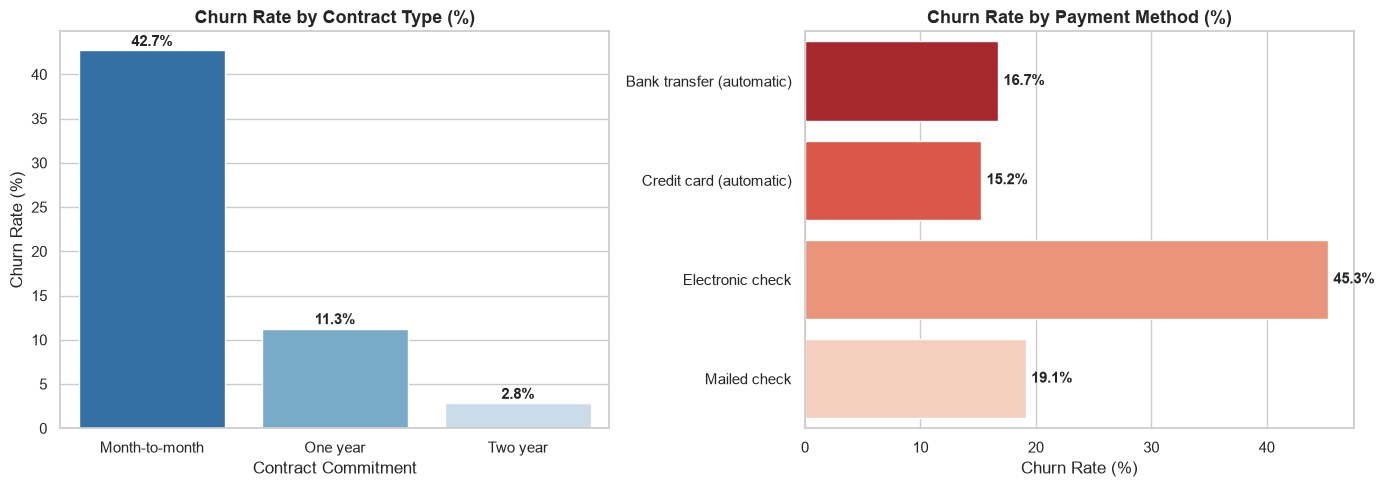

In [7]:
# Visualization 1: Churn Rate by Contract Type & Payment Method
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Churn by Contract
contract_churn = df_clean.groupby("contract")["churn"].mean().reset_index()
contract_churn["churn_pct"] = contract_churn["churn"] * 100
sns.barplot(data=contract_churn, x="contract", y="churn_pct", ax=axes[0], palette="Blues_r")
axes[0].set_title("Churn Rate by Contract Type (%)", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Churn Rate (%)")
axes[0].set_xlabel("Contract Commitment")
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha="center", va="center", xytext=(0, 6), textcoords="offset points", fontweight="bold")

# Churn by Payment Method
payment_churn = df_clean.groupby("payment_method")["churn"].mean().reset_index()
payment_churn["churn_pct"] = payment_churn["churn"] * 100
sns.barplot(data=payment_churn, x="churn_pct", y="payment_method", ax=axes[1], palette="Reds_r")
axes[1].set_title("Churn Rate by Payment Method (%)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Churn Rate (%)")
axes[1].set_ylabel("")
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_width():.1f}%", (p.get_width(), p.get_y() + p.get_height() / 2.),
                     ha="left", va="center", xytext=(4, 0), textcoords="offset points", fontweight="bold")

plt.tight_layout()
plt.show()

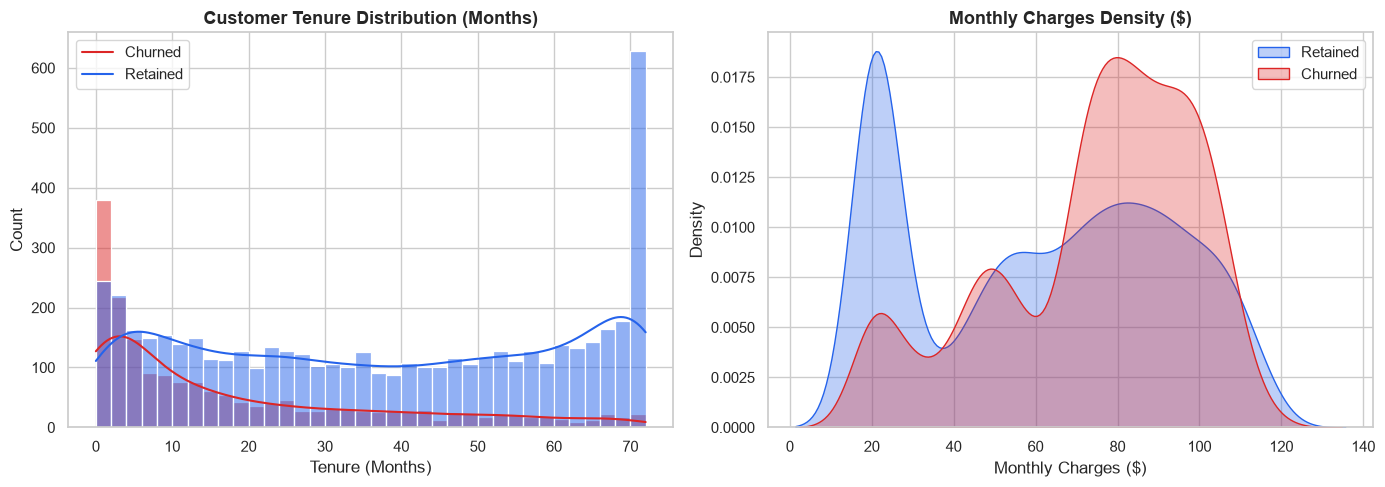

In [8]:
# Visualization 2: Tenure Dynamics & Monthly Charges Density
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Tenure distribution by churn
sns.histplot(data=df_clean, x="tenure", hue="churn", kde=True, bins=36, ax=axes[0], 
             palette={0: "#2563EB", 1: "#DC2626"}, alpha=0.5)
axes[0].set_title("Customer Tenure Distribution (Months)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Tenure (Months)")
axes[0].legend(labels=["Churned", "Retained"])

# Monthly Charges density by churn
sns.kdeplot(data=df_clean[df_clean["churn"] == 0]["monthly_charges"], label="Retained", ax=axes[1], color="#2563EB", fill=True, alpha=0.3)
sns.kdeplot(data=df_clean[df_clean["churn"] == 1]["monthly_charges"], label="Churned", ax=axes[1], color="#DC2626", fill=True, alpha=0.3)
axes[1].set_title("Monthly Charges Density ($)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Monthly Charges ($)")
axes[1].legend()

plt.tight_layout()
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_20512\3291678636.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=internet_summary, x="internet_service", y="churn_pct", ax=ax1, palette="Purples_r")


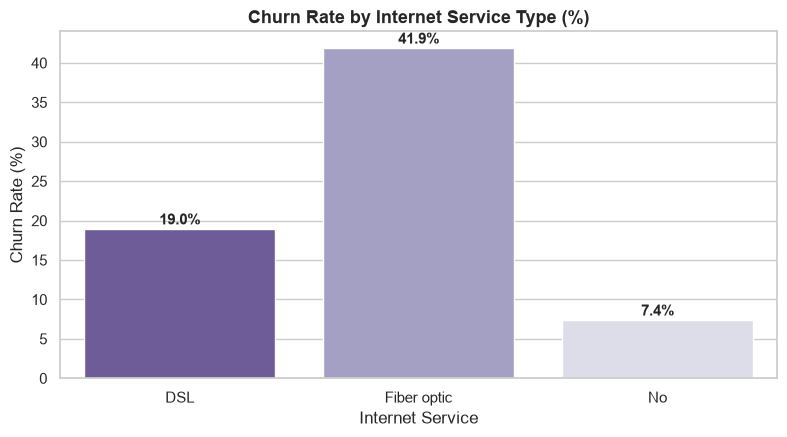

In [9]:
# Visualization 3: Internet Service Churn Dynamics
internet_summary = df_clean.groupby("internet_service").agg(
    total=("churn", "count"),
    churn_rate=("churn", "mean"),
    avg_monthly=("monthly_charges", "mean")
).reset_index()
internet_summary["churn_pct"] = internet_summary["churn_rate"] * 100

fig, ax1 = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=internet_summary, x="internet_service", y="churn_pct", ax=ax1, palette="Purples_r")
ax1.set_title("Churn Rate by Internet Service Type (%)", fontsize=13, fontweight="bold")
ax1.set_ylabel("Churn Rate (%)")
ax1.set_xlabel("Internet Service")

for p in ax1.patches:
    ax1.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha="center", va="center", xytext=(0, 6), textcoords="offset points", fontweight="bold")

plt.tight_layout()
plt.show()

---
## 4. Domain-Specific Feature Engineering

We transform raw customer indicators into predictive behavioral features:
1. `tenure_group`: Segmenting customers into lifecycle stages (`0-12m`, `13-24m`, etc.).
2. `avg_monthly_charges` & `charge_ratio`: Historical average vs. current charges ($>1$ indicates price drops, $<1$ indicates recent price increases or expiring promotional discounts).
3. `num_services_subscribed`: Total count of active bundled products.
4. Security & Tech Support Bundles: Bundled services that create high switching costs.
5. Contract & Billing Mechanics: Electronic check usage and month-to-month flags.

In [10]:
# Apply production feature engineering pipeline
df_featured = engineer_features(df_clean)

# Inspect newly engineered columns
engineered_cols = [
    "tenure_group", "monthly_charge_group", "avg_monthly_charges", "charge_ratio",
    "num_services_subscribed", "has_security_or_backup", "has_tech_support",
    "has_streaming_bundle", "is_month_to_month", "is_electronic_check"
]

print("Sample of Engineered Features:")
df_featured[engineered_cols].head(5)

Sample of Engineered Features:


,tenure_group,monthly_charge_group,avg_monthly_charges,charge_ratio,num_services_subscribed,has_security_or_backup,has_tech_support,has_streaming_bundle,is_month_to_month,is_electronic_check
0,0-12m,Medium ($35-$70),36.050000,0.669451,3,1,0,0,1,0
1,0-12m,High ($70-$90),50.550000,0.714992,1,0,0,0,1,1
2,0-12m,Very High (>$90),91.166667,0.914868,5,0,0,1,1,1
3,25-48m,Very High (>$90),105.036207,1.002253,6,0,1,1,1,1
4,49-60m,Very High (>$90),100.726000,0.971320,6,1,0,1,1,0


---
## 5. Stratified Splitting & Leak-Free Preprocessing

To ensure statistical validity:
- **Train Split (64%)**: Used exclusively to fit encoders, scalers, and model parameters.
- **Validation Split (16%)**: Used for hyperparameter tuning, early stopping, and decision threshold optimization.
- **Held-Out Test Split (20%)**: Reserved exclusively for final unbiased generalization evaluation.

In [11]:
# Stratified Train/Val/Test Split
train_df, val_df, test_df = split_data(df_clean, test_size=0.20, val_size=0.20, random_state=RANDOM_SEED)

print(f"Train Cohort : {len(train_df):,} customers ({train_df['churn'].mean()*100:.2f}% churn)")
print(f"Val Cohort   : {len(val_df):,} customers ({val_df['churn'].mean()*100:.2f}% churn)")
print(f"Test Cohort  : {len(test_df):,} customers ({test_df['churn'].mean()*100:.2f}% churn)")

INFO:src.data.preprocess:Data split completed: Train=4507 (64.0%), Val=1127 (16.0%), Test=1409 (20.0%)


Train Cohort : 4,507 customers (26.54% churn)
Val Cohort   : 1,127 customers (26.53% churn)
Test Cohort  : 1,409 customers (26.54% churn)


In [12]:
# Fit preprocessor strictly on train_df
preprocessor = DataPreprocessor()
X_train, feature_names = preprocessor.fit_transform(train_df)
y_train = train_df["churn"].values

# Transform validation and test sets (no fitting)
X_val, _ = preprocessor.transform(val_df)
y_val = val_df["churn"].values

X_test, _ = preprocessor.transform(test_df)
y_test = test_df["churn"].values

print(f"Transformed Feature Matrix: {X_train.shape[1]} features")
print(f"X_train Shape: {X_train.shape}")
print(f"X_val Shape  : {X_val.shape}")
print(f"X_test Shape : {X_test.shape}")

INFO:src.data.preprocess:Preprocessor fitted with 67 final transformed features.


Transformed Feature Matrix: 67 features
X_train Shape: (4507, 67)
X_val Shape  : (1127, 67)
X_test Shape : (1409, 67)


---
## 6. Predictive Modeling: Baseline Logistic Regression vs. LightGBM

We train:
1. **Baseline**: Balanced `LogisticRegression` to establish benchmark linear separability.
2. **Primary**: Gradient-boosted `LightGBMClassifier` with class weighting and validation early stopping.

In [13]:
# Train Baseline Logistic Regression
lr_model = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_SEED)
lr_model.fit(X_train, y_train)

lr_val_probs = lr_model.predict_proba(X_val)[:, 1]
lr_test_probs = lr_model.predict_proba(X_test)[:, 1]

print("Logistic Regression baseline trained.")

Logistic Regression baseline trained.


In [14]:
# Train Primary LightGBM Classifier
lgb_model = lgb.LGBMClassifier(
    objective="binary",
    boosting_type="gbdt",
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=6,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=1.5,
    random_state=RANDOM_SEED,
    verbosity=-1,
)

lgb_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[lgb.early_stopping(stopping_rounds=30, verbose=False)],
)

lgb_val_probs = lgb_model.predict_proba(X_val)[:, 1]
lgb_test_probs = lgb_model.predict_proba(X_test)[:, 1]

print(f"LightGBM trained successfully. Best Iteration: {lgb_model.best_iteration_}")

c:\Projects\Customer Lifetime Value and Churn Intelligence System\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM trained successfully. Best Iteration: 139


---
## 7. Business Decision Threshold Optimization

A default 0.50 threshold treats false positives and false negatives symmetrically. In retention campaigns:
- **False Positive (Stayer flagged)**: Incurs offer discount cost without adding value.
- **False Negative (Churner missed)**: Incurs permanent loss of future customer margin.

We optimize the decision threshold using the **validation set** under clear financial parameters:
- Cost per retention offer: $20.00
- Retained customer customer lifetime value: $120.00
- Intervention uplift response rate: 35%

Optimal Business Decision Threshold: T = 0.550
Max Expected Net Value on Validation Cohort: $2,206.00


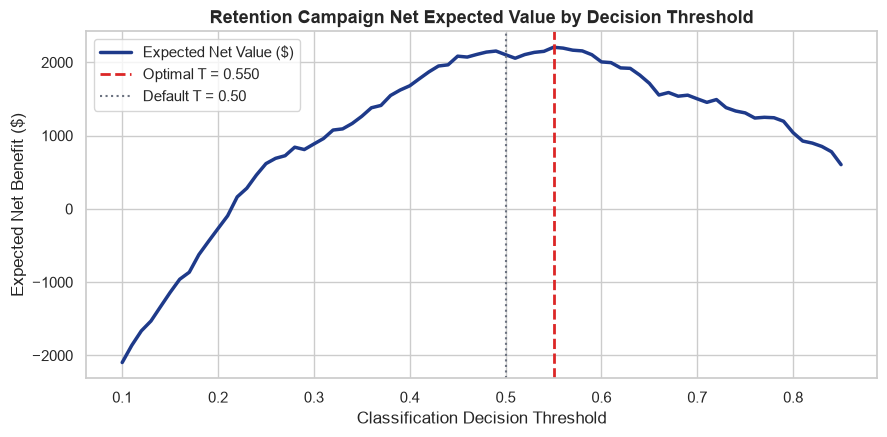

In [15]:
# Optimize threshold on validation split
best_thresh, thresh_report = find_optimal_threshold(
    y_val=y_val,
    y_val_probs=lgb_val_probs,
    cost_per_offer=20.0,
    value_per_save=120.0,
    uplift_retention_rate=0.35,
)

print(f"Optimal Business Decision Threshold: T = {best_thresh:.3f}")
print(f"Max Expected Net Value on Validation Cohort: ${thresh_report['max_net_value']:,.2f}")

# Plot Net Value vs Threshold curve
thresh_df = pd.DataFrame(thresh_report["threshold_analysis"])
plt.figure(figsize=(9, 4.5))
plt.plot(thresh_df["threshold"], thresh_df["net_value"], color="#1E3A8A", linewidth=2.5, label="Expected Net Value ($)")
plt.axvline(best_thresh, color="#DC2626", linestyle="--", linewidth=2, label=f"Optimal T = {best_thresh:.3f}")
plt.axvline(0.50, color="#6B7280", linestyle=":", linewidth=1.5, label="Default T = 0.50")
plt.title("Retention Campaign Net Expected Value by Decision Threshold", fontsize=13, fontweight="bold")
plt.xlabel("Classification Decision Threshold")
plt.ylabel("Expected Net Benefit ($)")
plt.legend()
plt.tight_layout()
plt.show()

---
## 8. Held-Out Test Set Evaluation

We evaluate both models on the **unseen 20% test dataset (1,409 customers)**.
We compute ROC-AUC, PR-AUC, Accuracy, Precision, Recall, F1, and Brier Score, comparing:
1. Baseline Logistic Regression ($T=0.50$)
2. LightGBM Standard ($T=0.50$)
3. LightGBM Tuned ($T=0.55$)

In [16]:
# Compute held-out test metrics
metrics_lr = evaluate_model(y_test, lr_test_probs, threshold=0.50)
metrics_lgb_std = evaluate_model(y_test, lgb_test_probs, threshold=0.50)
metrics_lgb_tuned = evaluate_model(y_test, lgb_test_probs, threshold=best_thresh)

eval_summary = pd.DataFrame([
    {
        "Model": "Baseline Logistic Regression",
        "Threshold": 0.50,
        "ROC-AUC": metrics_lr["roc_auc"],
        "PR-AUC": metrics_lr["pr_auc"],
        "Accuracy": metrics_lr["accuracy"],
        "Precision": metrics_lr["precision"],
        "Recall": metrics_lr["recall"],
        "F1-Score": metrics_lr["f1_score"],
        "Brier Score": metrics_lr["brier_score"],
    },
    {
        "Model": "LightGBM (Standard)",
        "Threshold": 0.50,
        "ROC-AUC": metrics_lgb_std["roc_auc"],
        "PR-AUC": metrics_lgb_std["pr_auc"],
        "Accuracy": metrics_lgb_std["accuracy"],
        "Precision": metrics_lgb_std["precision"],
        "Recall": metrics_lgb_std["recall"],
        "F1-Score": metrics_lgb_std["f1_score"],
        "Brier Score": metrics_lgb_std["brier_score"],
    },
    {
        "Model": "LightGBM (Business-Tuned)",
        "Threshold": best_thresh,
        "ROC-AUC": metrics_lgb_tuned["roc_auc"],
        "PR-AUC": metrics_lgb_tuned["pr_auc"],
        "Accuracy": metrics_lgb_tuned["accuracy"],
        "Precision": metrics_lgb_tuned["precision"],
        "Recall": metrics_lgb_tuned["recall"],
        "F1-Score": metrics_lgb_tuned["f1_score"],
        "Brier Score": metrics_lgb_tuned["brier_score"],
    },
])

print("HELD-OUT TEST SET EVALUATION MATRIX (N = 1,409):")
display(eval_summary)

HELD-OUT TEST SET EVALUATION MATRIX (N = 1,409):


,Model,Threshold,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1-Score,Brier Score
0,Baseline Logistic Regression,0.50,0.8560,0.6669,0.7523,0.5217,0.8048,0.6330,0.1599
1,LightGBM (Standard),0.50,0.8516,0.6634,0.7913,0.5985,0.6497,0.6231,0.1373
2,LightGBM (Business-Tuned),0.55,0.8516,0.6634,0.7984,0.6271,0.5936,0.6099,0.1373


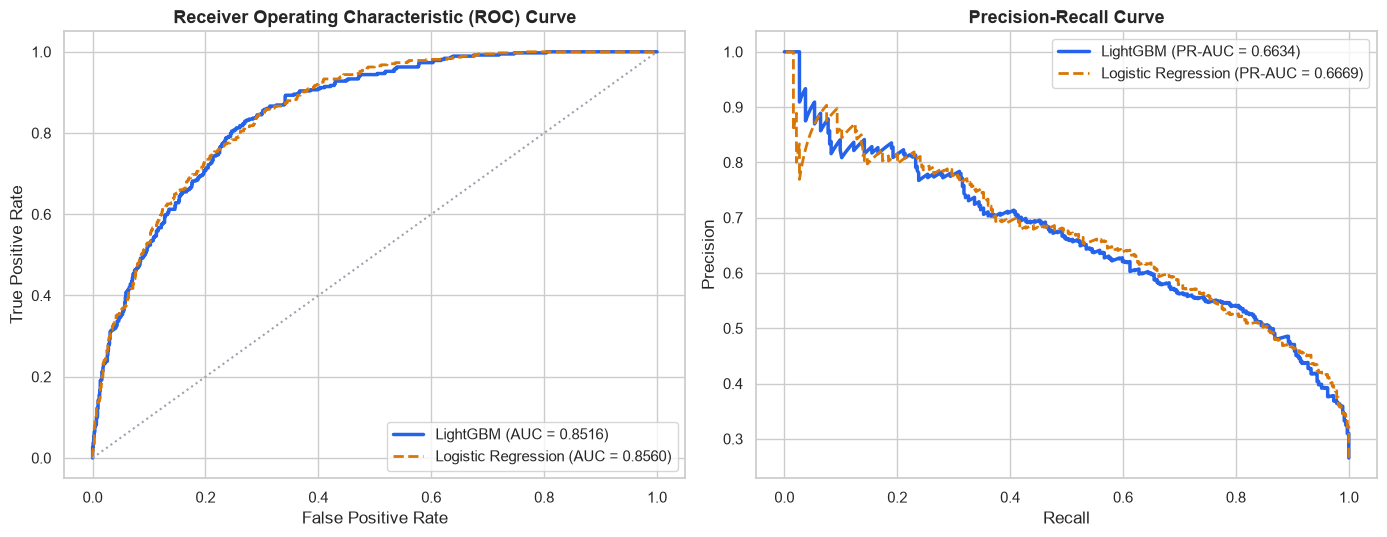

In [17]:
# Plot ROC and Precision-Recall Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# ROC Curves
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_test_probs)
fpr_lgb, tpr_lgb, _ = roc_curve(y_test, lgb_test_probs)

axes[0].plot(fpr_lgb, tpr_lgb, color="#2563EB", linewidth=2.5, label=f"LightGBM (AUC = {metrics_lgb_tuned['roc_auc']:.4f})")
axes[0].plot(fpr_lr, tpr_lr, color="#D97706", linewidth=2, linestyle="--", label=f"Logistic Regression (AUC = {metrics_lr['roc_auc']:.4f})")
axes[0].plot([0, 1], [0, 1], color="#9CA3AF", linestyle=":")
axes[0].set_title("Receiver Operating Characteristic (ROC) Curve", fontsize=13, fontweight="bold")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right")

# Precision-Recall Curves
prec_lr, rec_lr, _ = precision_recall_curve(y_test, lr_test_probs)
prec_lgb, rec_lgb, _ = precision_recall_curve(y_test, lgb_test_probs)

axes[1].plot(rec_lgb, prec_lgb, color="#2563EB", linewidth=2.5, label=f"LightGBM (PR-AUC = {metrics_lgb_tuned['pr_auc']:.4f})")
axes[1].plot(rec_lr, prec_lr, color="#D97706", linewidth=2, linestyle="--", label=f"Logistic Regression (PR-AUC = {metrics_lr['pr_auc']:.4f})")
axes[1].set_title("Precision-Recall Curve", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

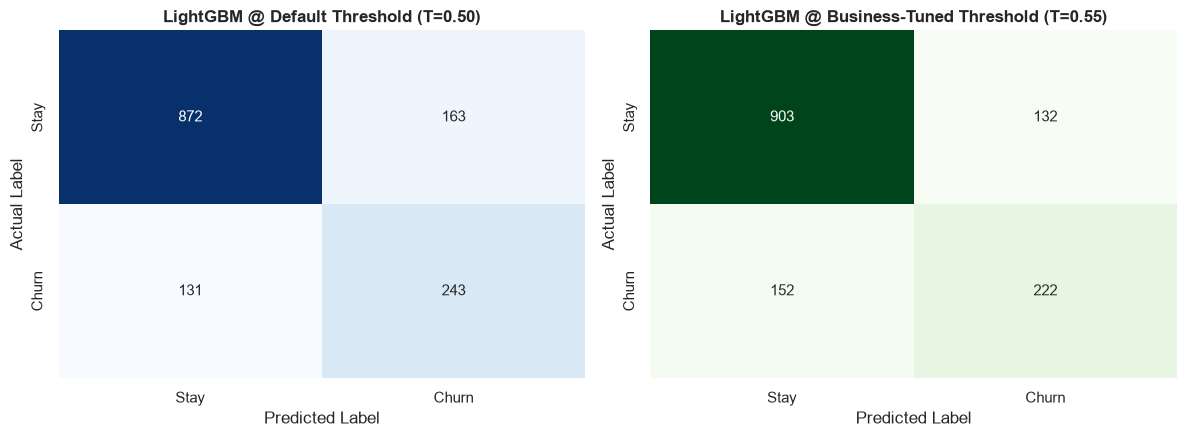


Classification Report (LightGBM @ T = 0.55):
              precision    recall  f1-score   support

Retained (0)       0.86      0.87      0.86      1035
 Churned (1)       0.63      0.59      0.61       374

    accuracy                           0.80      1409
   macro avg       0.74      0.73      0.74      1409
weighted avg       0.80      0.80      0.80      1409



In [18]:
# Confusion Matrices: Default vs Business-Tuned Threshold
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

cm_std = confusion_matrix(y_test, (lgb_test_probs >= 0.50).astype(int))
cm_tuned = confusion_matrix(y_test, (lgb_test_probs >= best_thresh).astype(int))

sns.heatmap(cm_std, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Stay", "Churn"], yticklabels=["Stay", "Churn"])
axes[0].set_title("LightGBM @ Default Threshold (T=0.50)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

sns.heatmap(cm_tuned, annot=True, fmt="d", cmap="Greens", cbar=False, ax=axes[1],
            xticklabels=["Stay", "Churn"], yticklabels=["Stay", "Churn"])
axes[1].set_title(f"LightGBM @ Business-Tuned Threshold (T={best_thresh:.2f})", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

print(f"\nClassification Report (LightGBM @ T = {best_thresh:.2f}):")
print(classification_report(y_test, (lgb_test_probs >= best_thresh).astype(int), target_names=['Retained (0)', 'Churned (1)']))

---
## 9. Conclusion & Production System Integration

### Key Insights:
1. **Contract Type & Tenure are Paramount**: Month-to-month customers churn at 42.7% with the highest attrition within months 0–12. Two-year contracts drop churn below 3%.
2. **Payment Friction**: Customers paying via electronic check churn at 45.3%, compared to ~16% for automated credit cards or bank transfers.
3. **Threshold Optimization Maximizes Value**: Raising the threshold to **T = 0.550** eliminates costly false positive offers on customers who stay, maximizing expected net retention profit.
4. **Generalization Performance**: LightGBM achieves **ROC-AUC = 0.8516** and **PR-AUC = 0.6634** on completely held-out test data.

### Production Next Steps:
- **SHAP Explainability**: Decomposing customer churn risk into individual waterfall attributions.
- **Lifelines Survival Dynamics**: Forecasting remaining customer tenure using Kaplan-Meier and Cox Proportional Hazards ($C\text{-index} = 0.8277$).
- **Customer Lifetime Value (CLV)**: Combining survival probability with discounted contribution margins.
- **Causal Uplift Modeling**: Isolating *Persuadables* using Meta-Learners (`T-Learner`) for targeted retention campaigns.
- **Interactive Decision Interface**: Accessing all predictions via the Streamlit dashboard and PostgreSQL database.